# Analyse et préparation des données immobilières

**Objectif du notebook :** charger les données, exécuter le pipeline de préparation et examiner les résultats, notamment les données conformes, les anomalies et les doublons potentiels.

> Les données utilisées sont **synthétiques** et ne doivent pas servir à estimer le marché (consignes du pack de données).

### Partie A : Chargement

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent          # notebooks/ → 07step7_reproductibilite/
assert (RACINE / "src").is_dir(), f"src/ introuvable depuis {Path.cwd()}"
sys.path.insert(0, str(RACINE))

In [2]:
# Importation
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src.analyse.statistiques import (
    ajouter_prix_m2,
    resultats_par_groupe,
    resumer,
    separer_transactions,
    statistiques_descriptives,
    vers_dataframe,
)
from src.main import charger_tout, executer_pipeline

In [3]:
# Chargement des sources
biens = charger_tout()
resultats = executer_pipeline(biens)
print(
    f"{len(resultats['propres'])} biens propres, "
    f"{len(resultats['quarantaine'])} en quarantaine, "
    f"sur {len(biens)} biens reçus."
)

2983 biens propres, 187 en quarantaine, sur 3184 biens reçus.


### Partie B : Qualité des données

#### B1. Bilan global

In [4]:
rapport = resultats["rapport"]
total = rapport["total_recus"]

indicateurs = [
    ("Reçus", total),
    ("Quarantaine", rapport["quarantaine"]),
    ("Avec avertissement", rapport["avec_avertissement"]),
    ("Corrigés", rapport["corriges"]),
    ("Entièrement conformes", rapport["entierement_conformes"]["nombre"]),
    ("Doublons exacts", rapport["doublons_exacts"]["nombre"]),
]

bilan_global = pd.DataFrame(indicateurs, columns=["indicateur", "nombre"]).set_index("indicateur")
bilan_global["% des reçus"] = bilan_global["nombre"] / total * 100

display(bilan_global.round(1))

,nombre,% des reçus
indicateur,,
Reçus,3184,100.0
Quarantaine,187,5.9
Avec avertissement,91,2.9
Corrigés,1216,38.2
Entièrement conformes,1834,57.6
Doublons exacts,14,0.4


Un bien « entièrement conforme » n’a nécessité ni mise en quarantaine, ni avertissement, ni correction. Le taux de 57,6 % ne signifie donc pas que les autres biens sont tous inutilisables : les 1 216 biens corrigés sont exclus de cette catégorie, même s’ils peuvent être exploitables après correction.

#### B2. Quarantaine par source

,reçus,quarantaine,taux de quarantaine (%)
particuliers,731,136,18.6
notaires,410,20,4.9
historique,528,10,1.9
agence,640,9,1.4
plateforme,875,12,1.4


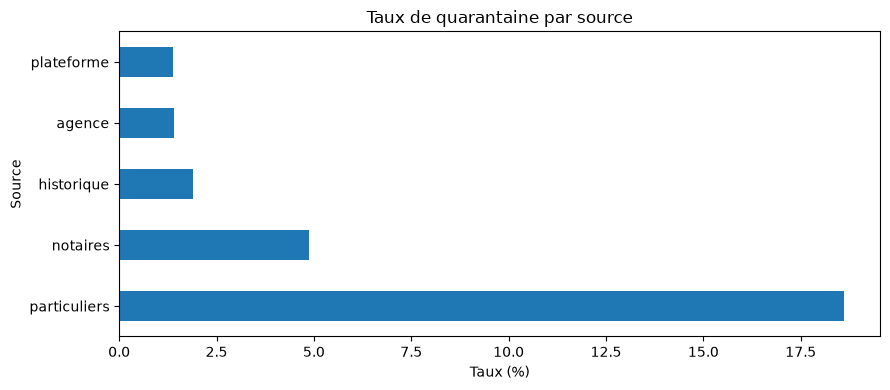

In [5]:
recus = pd.Series([b["source"] for b in biens]).value_counts()
en_quarantaine = pd.Series([q["bien"]["source"] for q in resultats["quarantaine"]]).value_counts()
bilan = pd.DataFrame({"reçus": recus, "quarantaine": en_quarantaine})
bilan["quarantaine"] = bilan["quarantaine"].fillna(0).astype(int)
bilan["taux de quarantaine (%)"] = bilan["quarantaine"] / bilan["reçus"] * 100
bilan = bilan.sort_values("taux de quarantaine (%)", ascending=False)

display(bilan.round(1))
ax = bilan["taux de quarantaine (%)"].plot(kind="barh", figsize=(9, 4))
ax.set(title="Taux de quarantaine par source", xlabel="Taux (%)", ylabel="Source")
plt.tight_layout()
plt.show()

Les particuliers concentrent 73 % de la quarantaine (136 biens sur 187) et ont le taux le plus élevé (18,6 %), ce qui confirme la qualité « faible » annoncée.

Les notaires, annoncés de qualité « très bonne », ont pourtant le **deuxième** taux (4,9 %), 3,5 fois celui de l'agence et de la plateforme (1,4 %). Ce sont surtout des prix absents et 6 dates impossibles (`32/13/2024`). Une source réputée fiable n'est pas une source sans erreur.

#### B3. Motifs de quarantaine

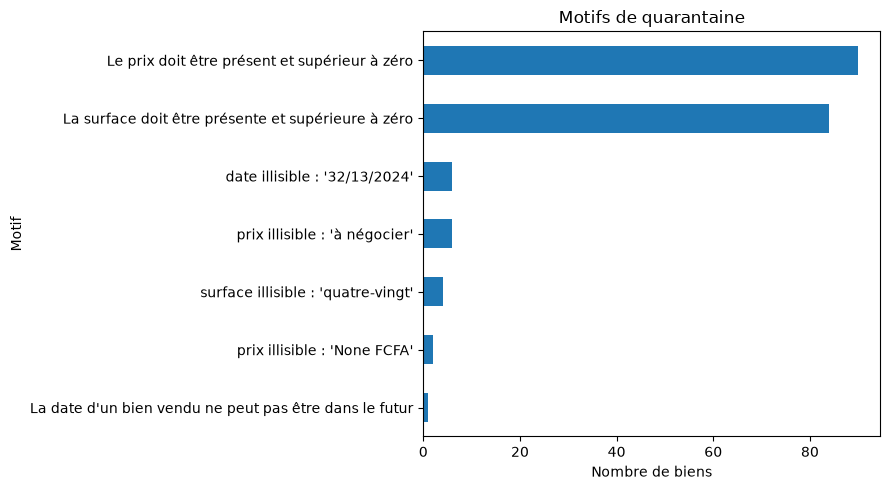

In [6]:
compteur = Counter()
for q in resultats["quarantaine"]:
    for motif in q["motifs"]:
        compteur[motif] += 1

serie = pd.Series(compteur).sort_values()
ax = serie.plot(kind="barh", figsize=(9, 5))
ax.set(title="Motifs de quarantaine", xlabel="Nombre de biens", ylabel="Motif")
plt.tight_layout()
plt.show()

Le graphique montre que les deux principaux motifs de quarantaine sont un prix absent ou non positif (90 cas) et une surface absente ou non positive (84 cas). Les 193 motifs dépassent les 187 biens en quarantaine parce qu’un même bien peut cumuler plusieurs motifs.

#### B4. Taux de conformité par règle

Forme initiale : (5, 14)
Les colonnes correspondent aux règles ; les lignes à leurs indicateurs.


,respectee,violee,non_evaluable,taux_conformite
salles_bain_atypiques,2095,88,1001,96.0
prix_positif,3086,98,0,96.9
surface_positive,3096,88,0,97.2
loyer_atypique,478,2,2704,99.6
prix_m2_hors_fourchette,2547,7,630,99.7
date_valide,3178,6,0,99.8
surface_atypique,3096,4,84,99.9
prix_atypique,2608,3,573,99.9
ville_region_coherentes,3172,4,8,99.9
transaction_valide,3184,0,0,100.0


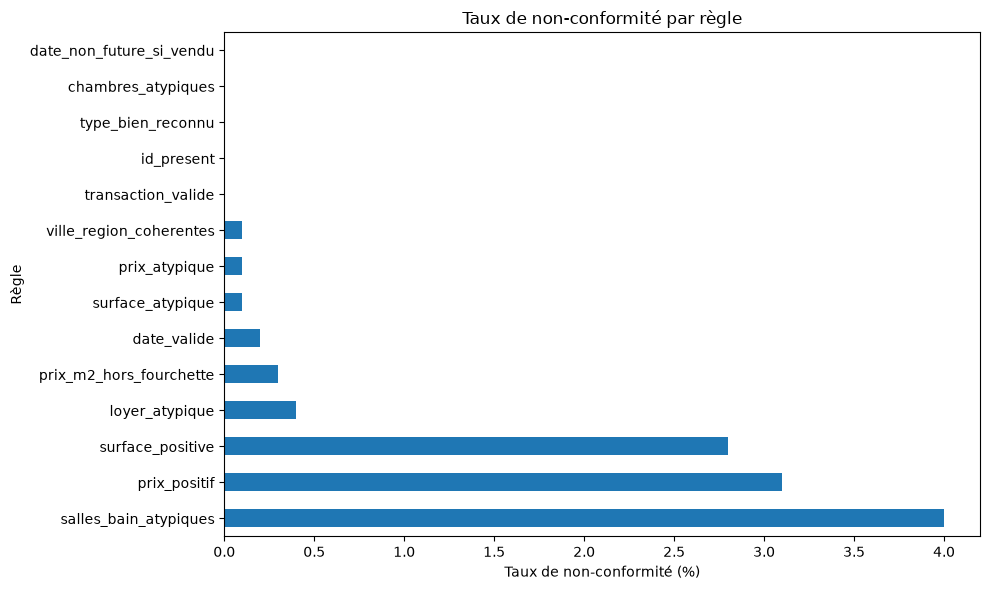

In [7]:
# Le DataFrame initial a une colonne par règle et une ligne par indicateur.
regles_brutes = pd.DataFrame(rapport["regles"])
print("Forme initiale :", regles_brutes.shape)
print("Les colonnes correspondent aux règles ; les lignes à leurs indicateurs.")

# Transposer pour obtenir une règle par ligne, puis conserver les indicateurs demandés.
colonnes = ["respectee", "violee", "non_evaluable", "taux_conformite"]
regles = regles_brutes.T[colonnes].sort_values("taux_conformite")
regles = regles.astype({"respectee": int, "violee": int, "non_evaluable": int})

display(regles)

# Taux de non-conformité : 100 % moins le taux de conformité fourni par le rapport.
taux_non_conformite = 100 - regles["taux_conformite"]

ax = taux_non_conformite.plot(kind="barh", figsize=(10, 6))
ax.set(
    title="Taux de non-conformité par règle",
    xlabel="Taux de non-conformité (%)",
    ylabel="Règle",
)
plt.tight_layout()
plt.show()

La règle la moins respectée est `salles_bain_atypiques` : son taux de conformité est de 96 %, ce qui indique que les valeurs de salles de bain méritent une vérification particulière. `loyer_atypique` compte 2 704 cas non évaluables parce qu’elle ne s’applique qu’aux locations ; les biens en vente sont exclus de ce contrôle.

#### B5. Valeurs manquantes

In [8]:
manquants = pd.DataFrame.from_dict(
    rapport["manquants_par_colonne"], orient="index", columns=["manquants"]
)
manquants["% des reçus"] = (manquants["manquants"] / total * 100).round(1)
display(manquants.sort_values("manquants", ascending=False))

# La périodicité n'a de sens que pour une location
ventes_recues = [b for b in biens if b["type_transaction"] == "vente"]
locations_recues = [b for b in biens if b["type_transaction"] == "location"]
periodicite = pd.DataFrame(
    {
        "biens": [len(ventes_recues), len(locations_recues)],
        "sans périodicité": [
            sum(b["periodicite"] is None for b in ventes_recues),
            sum(b["periodicite"] is None for b in locations_recues),
        ],
    },
    index=["ventes (sans objet)", "locations (vraiment manquante)"],
)
periodicite["%"] = (periodicite["sans périodicité"] / periodicite["biens"] * 100).round(1)
display(periodicite)

# salles_bain et statut : d'où viennent les valeurs manquantes ?
par_source = pd.DataFrame(biens).set_index("source")[["salles_bain", "statut"]].isna()
display(par_source.groupby(level=0).sum())

,manquants,% des reçus
periodicite,3007,94.4
statut,528,16.6
salles_bain,410,12.9
prix,85,2.7
surface,80,2.5
ville,8,0.3


,biens,sans périodicité,%
ventes (sans objet),2680,2680,100.0
locations (vraiment manquante),504,327,64.9


,salles_bain,statut
source,,
agence,0,0
historique,0,528
notaires,410,0
particuliers,0,0
plateforme,0,0


Le taux brut de manquants est trompeur pour trois colonnes :

- **`periodicite`** : pour les 2 680 ventes, elle est **sans objet**, puisqu'une vente se paie une fois. Elle manque **vraiment** pour 327 locations sur 504 (65 %) : celles de l'agence et des particuliers.
- **`salles_bain`** : les 410 valeurs manquantes sont les 410 biens des notaires. C'est une **colonne absente** de cette source, pas une valeur oubliée.
- **`statut`** : de même, les 528 valeurs manquantes sont les 528 biens de l'historique.

Seuls `prix`, `surface` et `ville` sont des données **réellement manquantes**, et elles restent rares (moins de 3 %).

### Partie C : Les distributions

Les distributions portent sur les **biens propres et uniques** (ni quarantaine, ni doublon exact). Les ventes et les locations sont toujours analysées **séparément** : un prix de vente et un loyer ne se comparent pas.

In [9]:
df = vers_dataframe(resultats["propres"])
ventes, locations = separer_transactions(df)
ventes = ajouter_prix_m2(ventes)          # prix au m² : ventes seulement
print(f"{len(ventes)} ventes et {len(locations)} locations propres.")

2534 ventes et 449 locations propres.


#### C1. Prix de vente

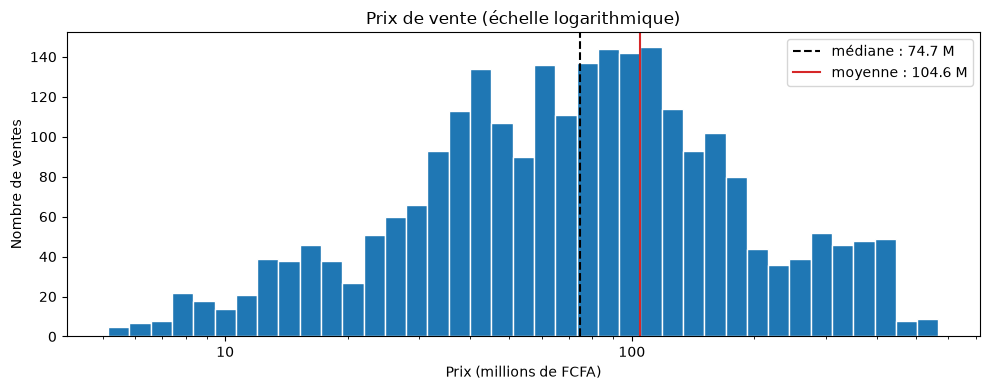

In [10]:
stats_prix = resumer(ventes["prix"])
prix_millions = ventes["prix"] / 1e6

# Intervalles réguliers en échelle logarithmique : chaque barre a la même largeur à l'écran
intervalles = np.logspace(np.log10(prix_millions.min()), np.log10(prix_millions.max()), 40)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(prix_millions, bins=intervalles, edgecolor="white")
ax.axvline(stats_prix["mediane"] / 1e6, color="black", linestyle="--",
           label=f"médiane : {stats_prix['mediane'] / 1e6:.1f} M")
ax.axvline(stats_prix["moyenne"] / 1e6, color="tab:red",
           label=f"moyenne : {stats_prix['moyenne'] / 1e6:.1f} M")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax.set(title="Prix de vente (échelle logarithmique)",
       xlabel="Prix (millions de FCFA)", ylabel="Nombre de ventes")
ax.legend()
plt.tight_layout()
plt.show()

Même en échelle logarithmique, les prix de vente ne forment pas une seule bosse : chaque type de bien a sa propre gamme de prix.

- **À gauche (moins de 20 M)**, surtout des chambres (59 %) et des studios (23 %).
- **Le plateau au-delà de 200 M** (12 % des ventes) est presque entièrement fait de villas (95 %).

La moyenne (104,6 M) est à droite de la médiane (74,7 M) : ces villas tirent la moyenne vers le haut. La médiane décrit mieux un prix « typique ». Mais un prix de vente global mélange des biens qui n'ont rien à voir : il faut comparer **par type de bien** (C3).

#### C2. Loyers

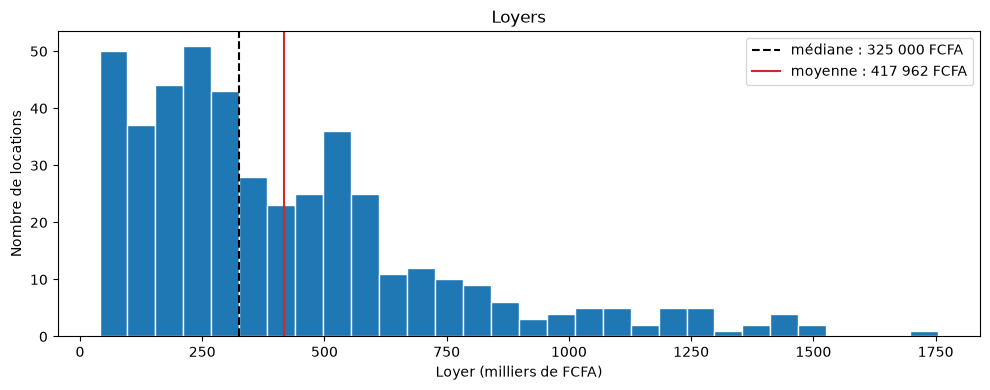

,nombre,mediane
source,,
agence,106,342500.0
particuliers,172,345000.0
plateforme,171,315000.0


In [11]:
stats_loyer = resumer(locations["prix"])
loyers_milliers = locations["prix"] / 1e3

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(loyers_milliers, bins=30, edgecolor="white")
ax.axvline(stats_loyer["mediane"] / 1e3, color="black", linestyle="--",
           label=f"médiane : {stats_loyer['mediane']:,.0f} FCFA".replace(",", " "))
ax.axvline(stats_loyer["moyenne"] / 1e3, color="tab:red",
           label=f"moyenne : {stats_loyer['moyenne']:,.0f} FCFA".replace(",", " "))
ax.set(title="Loyers", xlabel="Loyer (milliers de FCFA)", ylabel="Nombre de locations")
ax.legend()
plt.tight_layout()
plt.show()

# La périodicité n'est connue que pour la plateforme : les loyers sont-ils comparables ?
display(locations.groupby("source")["prix"].agg(nombre="count", mediane="median"))

Les loyers sont concentrés entre 50 000 et 600 000 FCFA, avec une longue traîne à droite jusqu'à 1 755 000 FCFA. Les 33 loyers au-dessus d'un million sont presque tous des villas (31). Comme pour les ventes, la moyenne (417 962) dépasse la médiane (325 000).

**Les loyers des trois sources sont du même ordre** (médianes de 315 000 à 345 000 FCFA), alors que la périodicité n'est connue que pour la plateforme (mensuelle). Cela laisse penser que les loyers de l'agence et des particuliers sont aussi mensuels. C'est une **hypothèse**, pas une preuve : la périodicité reste vide dans les données.

#### C3. Prix au m² par type de bien

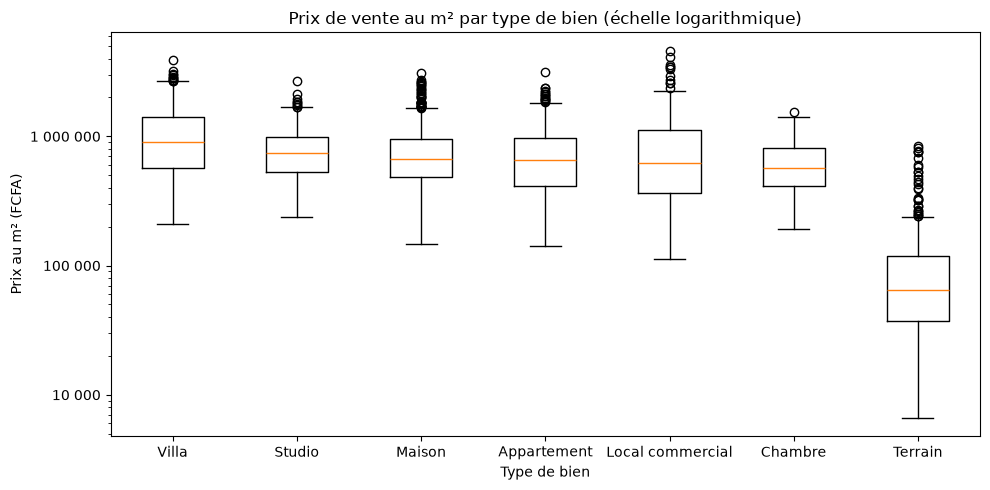

In [12]:
# Types triés par médiane décroissante
ordre = ventes.groupby("type_bien")["prix_m2"].median().sort_values(ascending=False).index
groupes = [ventes.loc[ventes["type_bien"] == t, "prix_m2"].dropna() for t in ordre]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(groupes, tick_labels=list(ordre))
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}".replace(",", " ")))
ax.set(title="Prix de vente au m² par type de bien (échelle logarithmique)",
       xlabel="Type de bien", ylabel="Prix au m² (FCFA)")
plt.tight_layout()
plt.show()

**Pourquoi une échelle logarithmique ?** Le prix au m² médian du terrain (64 765 FCFA) est environ dix fois plus bas que celui des autres types (570 000 à 900 000), et quelques valeurs dépassent 4 millions. Sur un axe linéaire, la boîte du terrain serait écrasée contre le bas du graphique, et toutes les autres boîtes seraient tassées par les valeurs extrêmes. L'échelle logarithmique compare les **rapports** : chaque graduation multiplie la précédente par 10.

**Lecture :**
- **La villa a le prix au m² le plus élevé**, et la chambre le plus bas des logements.
- **Le local commercial a la plus grande dispersion** : sa boîte est la plus haute et monte jusqu'à 4,6 M FCFA/m².
- **Le terrain est à part** : sans construction, son m² vaut beaucoup moins. Ses nombreux points au-dessus de la moustache (29 terrains à plus de 240 000 FCFA/m²) sont des terrains chers *pour un terrain*, mais pas des erreurs : ils restent dans la fourchette du référentiel. Mélanger terrains et logements ferait baisser toutes les moyennes.

#### C4. Statistiques descriptives

In [13]:
stats_ventes = statistiques_descriptives(ventes, ("prix", "surface", "prix_m2"))
stats_locations = statistiques_descriptives(locations, ("prix", "surface"))

tableau = pd.concat(
    {"ventes": pd.DataFrame(stats_ventes), "locations": pd.DataFrame(stats_locations)},
    axis=1,
)
# Affichage avec séparateur de milliers, sans décimales
display(tableau.map(lambda x: f"{x:,.0f}".replace(",", " ")))

ventes                     locations        
                   prix surface    prix_m2       prix surface
nombre            2 534   2 534      2 534        449     449
moyenne     104 550 271     237    735 795    417 962     265
mediane      74 740 000     147    624 852    325 000     150
ecart_type   98 249 500     286    561 671    319 231     328
minimum       5 156 000      10      6 648     40 000      10
q1           38 818 250      71    353 490    185 000      80
q3          129 400 250     248    979 080    550 000     241
maximum     567 559 000   1 495  4 603 188  1 755 000   1 475

Pour **toutes** les mesures, la moyenne est au-dessus de la médiane : les distributions sont étirées vers les grandes valeurs. C'est aussi vrai pour les surfaces (médiane 147 m², moyenne 237 m² pour les ventes), à cause des terrains, qui vont jusqu'à 1 495 m².

L'écart-type est du même ordre que la moyenne (98 M pour 105 M sur les prix de vente) : les prix sont très dispersés. Le tableau confirme qu'un résumé en un seul chiffre ne suffit pas. Il faut donner la médiane **et** les quartiles, et séparer les types de bien.

### Partie D : Les anomalies

Les parties B et C donnent des chiffres. Cette partie montre **des cas réels**, pour voir à quoi ressemble chaque type d'anomalie. Le cahier des charges demande de distinguer l'**erreur certaine** (quarantaine), la **valeur atypique** (avertissement) et le **cas ambigu** (doublon probable).

#### D1. Quarantaine : un exemple par motif

In [14]:
# Le bien est gardé BRUT en quarantaine : on voit ce que la source a écrit
exemples = {}
for q in resultats["quarantaine"]:
    for motif in q["motifs"]:
        exemples.setdefault(motif, q)          # le premier bien rencontré pour ce motif

colonnes_utiles = ["source", "id_local", "type_bien", "prix", "surface", "date", "statut"]
lignes = []
for motif, q in exemples.items():
    ligne = {"motif": motif, "nombre de biens": compteur[motif]}
    ligne.update({c: q["bien"][c] for c in colonnes_utiles})
    lignes.append(ligne)

display(pd.DataFrame(lignes).sort_values("nombre de biens", ascending=False).set_index("motif"))

,nombre de biens,source,id_local,type_bien,prix,surface,date,statut
motif,,,,,,,,
Le prix doit être présent et supérieur à zéro,90,agence,AGT-00950,Appartement,0,66.6,23/12/2019,Vendu
La surface doit être présente et supérieure à zéro,84,plateforme,PLT-00211,Appartement,595000,,2020-08-07,Loué
prix illisible : 'à négocier',6,plateforme,PLT-00062,Terrain,à négocier,1131.9,2023-04-04,En vente
date illisible : '32/13/2024',6,notaires,NOT-02394,Maison,69528000.0,238.3,32/13/2024,VENDU
surface illisible : 'quatre-vingt',4,particuliers,PRT-01778,Villa,705000,quatre-vingt,03/06/2020,Loué
prix illisible : 'None FCFA',2,particuliers,PRT-01563,Studio,None FCFA,32.4,2019-08-24,En vente
La date d'un bien vendu ne peut pas être dans le futur,1,plateforme,PLT-00077,Appartement,64862000,78.4,2028-12-01,Vendu


Ces biens sont des **erreurs certaines** : on ne peut pas les garder sans inventer une valeur.

- **Valeurs absentes ou impossibles** : un appartement « Vendu » à 0 FCFA (AGT-00950), une surface vide (PLT-00211). Ce sont les deux motifs principaux (90 et 84 biens).
- **Texte à la place d'un nombre** : `'à négocier'`, `'None FCFA'`, `'quatre-vingt'`. On pourrait deviner que « quatre-vingt » veut dire 80 m², mais `regles_metier.md` n'autorise que les corrections fiables : on ne devine pas.
- **Dates impossibles** : `32/13/2024` chez les notaires (13ᵉ mois), ou un bien « Vendu » daté de 2028 (PLT-00077).

Le tableau montre les valeurs **telles que la source les a écrites** : date `23/12/2019`, statut `VENDU` en majuscules. Ces deux défauts étaient normalisables, mais le bien est en quarantaine pour une autre raison, et on garde la donnée brute pour que la personne qui la relit voie l'original.

#### D2. Avertissements : un exemple par raison

In [15]:
# Seuls les biens conservés nous intéressent ici (les autres sont déjà en quarantaine)
propres_par_id = {b["id_local"]: b for b in resultats["propres"]}
avertissements = [(i, raison) for i, raison in resultats["avertissements"] if i in propres_par_id]

raisons = pd.Series([raison for _, raison in avertissements]).value_counts()
display(raisons.rename("nombre d'avertissements").to_frame())

colonnes_utiles = ["source", "id_local", "type_bien", "type_transaction", "prix", "surface",
                   "chambres", "salles_bain", "ville", "region"]
premier = {}
for i, raison in avertissements:
    premier.setdefault(raison, propres_par_id[i])
display(pd.DataFrame(premier).T[colonnes_utiles])

,nombre d'avertissements
salles_bain_atypiques,83
prix_m2_hors_fourchette,4
ville_region_coherentes,4


,source,id_local,type_bien,type_transaction,prix,surface,chambres,salles_bain,ville,region
salles_bain_atypiques,plateforme,PLT-00073,Appartement,vente,27408000.0,175.0,1,4,Vélingara,Kolda
prix_m2_hors_fourchette,agence,AGT-01035,Studio,vente,59204000,22,5,4,Rufisque,Dakar
ville_region_coherentes,particuliers,PRT-01714,Appartement,vente,27884000,158.9,6,2,Dakar,Ziguinchor


Parmi les biens conservés, 91 avertissements, dont 83 pour `salles_bain_atypiques`. Ce sont des **valeurs atypiques** : improbables, mais pas impossibles. Le bien est gardé, et l'anomalie est signalée.

- **PLT-00073** : un appartement avec 1 chambre et 4 salles de bain. C'est possible (un bureau aménagé, par exemple), mais peu probable : à vérifier.
- **PRT-01714** : la ville est Dakar, mais la région est Ziguinchor. On ne corrige pas, parce qu'on ne sait pas laquelle des deux est fausse.
- **AGT-01035** : un studio de 22 m² vendu 59 M FCFA, soit environ 2,7 M FCFA/m², au-dessus de la fourchette du studio (2,25 M). Le même bien a **5 chambres et 4 salles de bain dans 22 m²** : c'est plus probablement une erreur de type de bien ou de surface qu'un prix élevé. Aucune règle ne contrôle le nombre de chambres d'un studio : c'est une limite de nos contrôles.

Les autres avertissements (`loyer_atypique`, `prix_atypique`, `surface_atypique`) n'apparaissent pas ici : ils concernent des biens déjà partis en quarantaine pour un autre motif.

#### D3. Doublons probables

In [16]:
# Même type, même ville, même surface, même transaction, mais identifiants différents
lignes = []
for numero, groupe in enumerate(resultats["doublons_probables"], start=1):
    for bien in groupe:
        lignes.append({"groupe": numero, **bien})

doublons = pd.DataFrame(lignes).set_index(["groupe", "id_local"])
display(doublons[["source", "type_bien", "ville", "surface", "prix", "chambres", "salles_bain", "date"]])

source    type_bien          ville  surface  \
groupe id_local                                                       
1      PLT-00157    plateforme  Appartement     Ziguinchor    110.0   
       PLT-00280    plateforme  Appartement     Ziguinchor    110.0   
2      AGT-00963        agence  Appartement  Joal-Fadiouth    123.7   
       PRT-01604  particuliers  Appartement  Joal-Fadiouth    123.7   
3      AGT-01042        agence       Studio     Bounkiling     41.0   
       PRT-02173  particuliers       Studio     Bounkiling     41.0   
4      AGT-01098        agence  Appartement          Thiès    168.0   
       NOT-02557      notaires  Appartement          Thiès    168.0   
5      AGT-01179        agence  Appartement      Vélingara    158.7   
       HIS-0071     historique  Appartement      Vélingara    158.7   
6      AGT-01195        agence  Appartement  Joal-Fadiouth     58.1   
       PRT-02151  particuliers  Appartement  Joal-Fadiouth     58.1   
7      PRT-01461  particuliers       Studio         Gossas     50.0   
       PRT-02191  particuliers       Studio         Gossas     50.0   
8      PRT-01967  particuliers       Maison      Koungheul    243.5   
       NOT-02269      notaires       Maison      Koungheul    243.5   

                         prix  chambres  salles_bain        date  
groupe id_local                                                   
1      PLT-00157   39664000.0         6          2.0  2020-09-07  
       PLT-00280  100671000.0         5          4.0  2018-08-21  
2      AGT-00963   27722000.0         6          1.0  2021-07-02  
       PRT-01604   30452000.0         6          2.0  2022-12-20  
3      AGT-01042   21681000.0         5          4.0  2020-01-31  
       PRT-02173   24122000.0         4          3.0  2025-09-26  
4      AGT-01098   64976000.0         1          4.0  2023-05-19  
       NOT-02557  121510000.0         2          NaN  2020-09-07  
5      AGT-01179  114867000.0         6          2.0  2020-07-22  
       HIS-0071   115100000.0         2          3.0  2018-02-27  
6      AGT-01195   47508000.0         6          4.0  2024-11-16  
       PRT-02151  118235000.0         6          4.0  2025-11-07  
7      PRT-01461   18152000.0         4          4.0  2022-05-11  
       PRT-02191   17244400.0         4          4.0  2025-06-01  
8      PRT-01967   50875000.0         1          3.0  2019-07-10  
       NOT-02269   66566000.0         4          NaN  2020-11-23

Les 8 groupes partagent le même type, la même ville, la même surface et la même transaction. Ce sont des **cas ambigus** : il faut les regarder un par un.

- **Groupes 2 et 7 : probablement le même bien.** Même nombre de chambres et prix proches (5 à 10 % d'écart). Dans le groupe 7, les deux annonces viennent des particuliers, à trois ans d'intervalle : sans doute une remise en vente.
- **Groupe 5 : douteux.** Les prix sont presque identiques (114,9 M et 115,1 M), mais il y a 6 chambres d'un côté et 2 de l'autre.
- **Groupes 1, 4, 6 et 8 : probablement des coïncidences.** Le prix varie du simple au double (×1,3 à ×2,5), ou le nombre de chambres est très différent.

Cela confirme le choix de l'étape 4 : **signaler sans fusionner**. Une surface identique au dixième de m² rapproche les biens, mais seule une vérification humaine peut trancher. Fusionner automatiquement aurait mélangé des biens différents.

### Partie E : Prix au m² par ville et par région

**Pourquoi retirer les terrains ?** Le prix au m² d'un terrain est environ dix fois plus bas que celui d'un logement (C3), et la part de terrains varie beaucoup d'une ville à l'autre. Une ville qui compte beaucoup de terrains paraîtrait moins chère, même si ses logements ne le sont pas. C'est un **effet de composition** : on comparerait des mélanges différents, pas des prix. On compare donc les **ventes hors terrains**.

In [17]:
part_terrains = ventes.groupby("ville")["type_bien"].apply(lambda types: (types == "Terrain").mean() * 100)
print(f"Part de terrains par ville : de {part_terrains.min():.0f} % à {part_terrains.max():.0f} %")

logements = ventes[ventes["type_bien"] != "Terrain"]
print(f"{len(logements)} ventes hors terrains, sur {len(ventes)} ventes.")

Part de terrains par ville : de 4 % à 34 %
2177 ventes hors terrains, sur 2534 ventes.


#### E1. Par ville

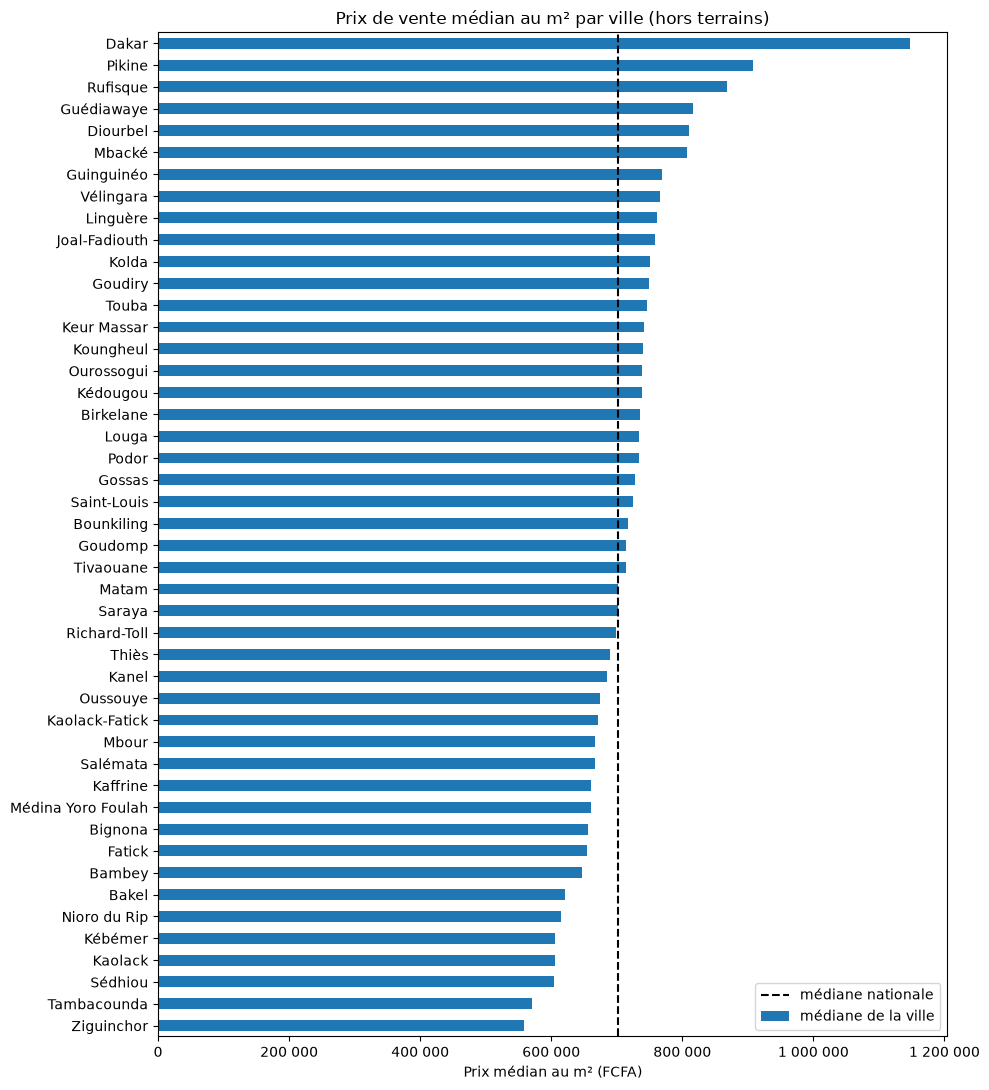

Les 5 villes les plus chères et les 5 moins chères :


,nombre,moyenne,mediane,part de terrains (%)
ville,,,,
Dakar,40,1171575.0,1147198.0,9.0
Pikine,35,1056730.0,907602.0,17.0
Rufisque,48,1078102.0,868408.0,11.0
Guédiawaye,30,944977.0,815961.0,25.0
Diourbel,32,954788.0,809737.0,16.0
Kébémer,71,735112.0,606344.0,7.0
Kaolack,47,753253.0,606231.0,10.0
Sédhiou,53,850916.0,604237.0,12.0
Tambacounda,45,724675.0,570511.0,13.0


In [18]:
par_ville = resultats_par_groupe(logements, "ville", "prix_m2")
par_ville["part de terrains (%)"] = part_terrains.round(0)    # part dans TOUTES les ventes de la ville

fig, ax = plt.subplots(figsize=(10, 11))
par_ville["mediane"].sort_values().plot(kind="barh", ax=ax, label="médiane de la ville")
ax.axvline(logements["prix_m2"].median(), color="black", linestyle="--", label="médiane nationale")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set(title="Prix de vente médian au m² par ville (hors terrains)",
       xlabel="Prix médian au m² (FCFA)", ylabel="")
ax.legend()
plt.tight_layout()
plt.show()

print("Les 5 villes les plus chères et les 5 moins chères :")
display(pd.concat([par_ville.head(5), par_ville.tail(5)]).round(0))

**Dakar est nettement en tête** (1 147 198 FCFA/m², 63 % au-dessus de la médiane nationale de 701 820), suivie de sa périphérie : Pikine, Rufisque et Guédiawaye. Le prix au m² médian varie du simple au double entre Dakar et Ziguinchor, la moins chère. Hors de la région de Dakar, les villes sont proches les unes des autres, entre 560 000 et 810 000 FCFA/m².

**L'effet de composition est réel.** Avec les terrains, le classement change beaucoup. Keur Massar, où 34 % des ventes sont des terrains, passe de la **dernière** place (46ᵉ) à la 14ᵉ. Guédiawaye (25 % de terrains) passe de la 13ᵉ à la 4ᵉ. À l'inverse, Saint-Louis (4 % de terrains) recule de la 4ᵉ à la 22ᵉ place. Sans ce filtre, on aurait conclu à tort que Keur Massar est la ville la moins chère.

Chaque ville compte entre 19 et 71 ventes hors terrains : les médianes sont calculées sur assez de biens pour être lues, mais un écart de quelques dizaines de milliers de FCFA entre deux villes n'est pas significatif.

#### E2. Par région

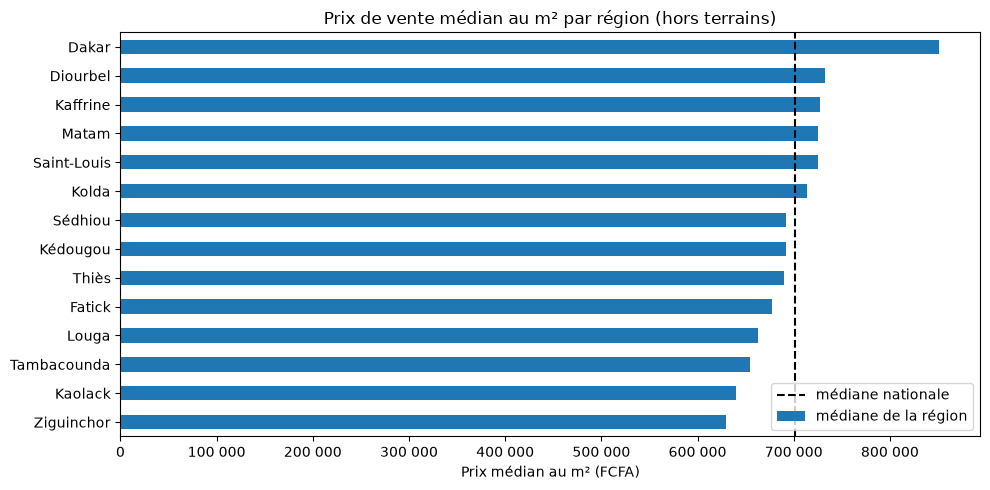

,nombre,moyenne,mediane
region,,,
Dakar,170,1050207.0,851098.0
Diourbel,163,923166.0,732300.0
Kaffrine,155,775289.0,727458.0
Matam,163,858105.0,724893.0
Saint-Louis,145,872222.0,724840.0
Kolda,159,768001.0,713514.0
Sédhiou,170,824769.0,692258.0
Kédougou,137,868300.0,692019.0
Thiès,156,849801.0,689937.0


In [19]:
par_region = resultats_par_groupe(logements, "region", "prix_m2")

fig, ax = plt.subplots(figsize=(10, 5))
par_region["mediane"].sort_values().plot(kind="barh", ax=ax, label="médiane de la région")
ax.axvline(logements["prix_m2"].median(), color="black", linestyle="--", label="médiane nationale")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set(title="Prix de vente médian au m² par région (hors terrains)",
       xlabel="Prix médian au m² (FCFA)", ylabel="")
ax.legend()
plt.tight_layout()
plt.show()

display(par_region.round(0))

**La région de Dakar est la plus chère** (851 098 FCFA/m²), environ 16 % au-dessus de la deuxième, Diourbel (732 300). Les 13 autres régions sont **très proches** : de 629 284 (Ziguinchor) à 732 300 FCFA/m², soit environ 16 % d'écart.

La région lisse les différences entre villes : la moyenne de Dakar (1 050 207) est bien au-dessus de sa médiane, parce que la région mélange Dakar-ville, très chère, et des communes moins chères. À l'échelle régionale, on retiendra une seule opposition nette : **Dakar contre le reste du pays**.

### Partie F : Conclusions

#### Qualité des données

- **Sur 3 184 biens reçus, 187 (5,9 %) sont en quarantaine** pour une erreur certaine : prix ou surface absents ou impossibles, texte à la place d'un nombre, date impossible. 91 biens conservés portent un avertissement, et 14 doublons exacts ont été retirés. Il reste **2 983 biens propres et uniques**.
- **Les particuliers concentrent 73 % de la quarantaine** (18,6 % de leurs biens), ce qui confirme leur qualité « faible ». **Les notaires**, de qualité « très bonne », ont pourtant le deuxième taux (4,9 %) : une source réputée fiable n'est pas une source sans erreur.
- **Seuls 57,6 % des biens sont entièrement conformes** dès leur arrivée. Les autres ont surtout demandé des corrections fiables (1 216 biens : formats de date, séparateurs de milliers, synonymes), et non des rejets.
- **Les taux bruts de valeurs manquantes trompent.** La périodicité « manque » à 94 %, mais elle est sans objet pour les ventes : elle manque vraiment pour 65 % des locations. `salles_bain` et `statut` sont des colonnes absentes d'une source entière.

#### Principaux résultats d'analyse

- **Ventes et locations ne se comparent pas** : prix de vente médian 74,7 M FCFA, loyer médian 325 000 FCFA.
- **Toutes les distributions sont étirées vers la droite** : la moyenne dépasse la médiane, et la médiane décrit mieux un prix typique.
- **Le type de bien est le premier facteur de prix.** Le prix au m² médian va de 64 765 FCFA pour un terrain à 906 133 FCFA pour une villa. Un prix moyen « tous biens confondus » n'a pas de sens.
- **Dakar et sa périphérie sont les plus chers**, hors terrains. Les écarts entre les autres régions sont faibles.

#### Décisions et limites

- **Les doublons probables sont signalés, jamais fusionnés.** La moitié des 8 groupes ressemblent à des coïncidences (D3).
- **La périodicité des loyers de l'agence et des particuliers est inconnue.** Leurs loyers ressemblent à ceux de la plateforme, qui sont mensuels, mais c'est une hypothèse (C2). Pour cette raison, le prix au m² n'est calculé que pour les ventes.
- **La fourchette de prix au m² est large** (déduite des bornes indicatives du référentiel) : elle ne détecte que les incohérences grossières.
- **Certaines incohérences ne sont contrôlées par aucune règle**, par exemple un studio de 22 m² avec 5 chambres (D2).
- **Les données sont synthétiques** : ces résultats illustrent la démarche, et ne décrivent pas le marché immobilier sénégalais.

#### Reproduire ce notebook

Depuis la racine du projet : créer le venv, puis `pip install -r requirements.txt`. Ouvrir `07step7_reproductibilite/notebooks/01_exploration.ipynb` avec le noyau du venv, puis **Redémarrer le noyau et Tout exécuter**. Toutes les valeurs sont recalculées à partir des fichiers de `sources/`, qui ne sont jamais modifiés.